In [ ]:
import os
HOME = os.getcwd()
print(HOME)

/content


## Install dependencies

In [1]:
%%capture
!pip install -q ultralytics roboflow

## Imports

In [2]:
from roboflow import Roboflow
from google.colab import userdata
from IPython.display import Image

## Pull dataset

In [3]:
!mkdir {HOME}/datasets
%cd {HOME}/datasets

ROBOFLOW_API_KEY = userdata.get('roboflow_api_key')
rf = Roboflow(api_key=ROBOFLOW_API_KEY)

project = rf.workspace("roboflow-jvuqo").project("football-ball-detection-rejhg")
version = project.version(2)
dataset = version.download("yolov8")

mkdir: cannot create directory ‘{HOME}/datasets’: No such file or directory
[Errno 2] No such file or directory: '{HOME}/datasets'
/content
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to football-ball-detection-2 in yolov8:: 100%|██████████| 4434/4434 [00:00<00:00, 5950.76it/s]


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


**NOTE:** Update `data.yaml` structure to align with the latest requirements of the `ultralytics` package.



In [ ]:
!sed -i 's|\(train: \).*|\1../train/images|' {dataset.location}/data.yaml
!sed -i 's|\(val: \).*|\1../valid/images|' {dataset.location}/data.yaml

## Custom training

In [ ]:
%cd {HOME}

!yolo task=detect mode=train model=yolo26s-objv1-150.pt name=yolo26s data={dataset.location}/data.yaml batch=12 epochs=200 patience=30 imgsz=1280 plots=True

/content
Ultralytics 8.4.193 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA A100-SXM4-80GB, 81153MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=12, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datasets/football-ball-detection-2/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=200, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1280, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s-objv1-150.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yo

In [ ]:
!ls {HOME}/runs/detect/train/

args.yaml					   R_curve.png		val_batch0_labels.jpg
confusion_matrix_normalized.png			   results.csv		val_batch0_pred.jpg
confusion_matrix.png				   results.png		val_batch1_labels.jpg
events.out.tfevents.1721903784.c5e077934c7c.748.0  train_batch0.jpg	val_batch1_pred.jpg
F1_curve.png					   train_batch1.jpg	val_batch2_labels.jpg
labels_correlogram.jpg				   train_batch2.jpg	val_batch2_pred.jpg
labels.jpg					   train_batch6560.jpg	weights
P_curve.png					   train_batch6561.jpg
PR_curve.png					   train_batch6562.jpg


/content


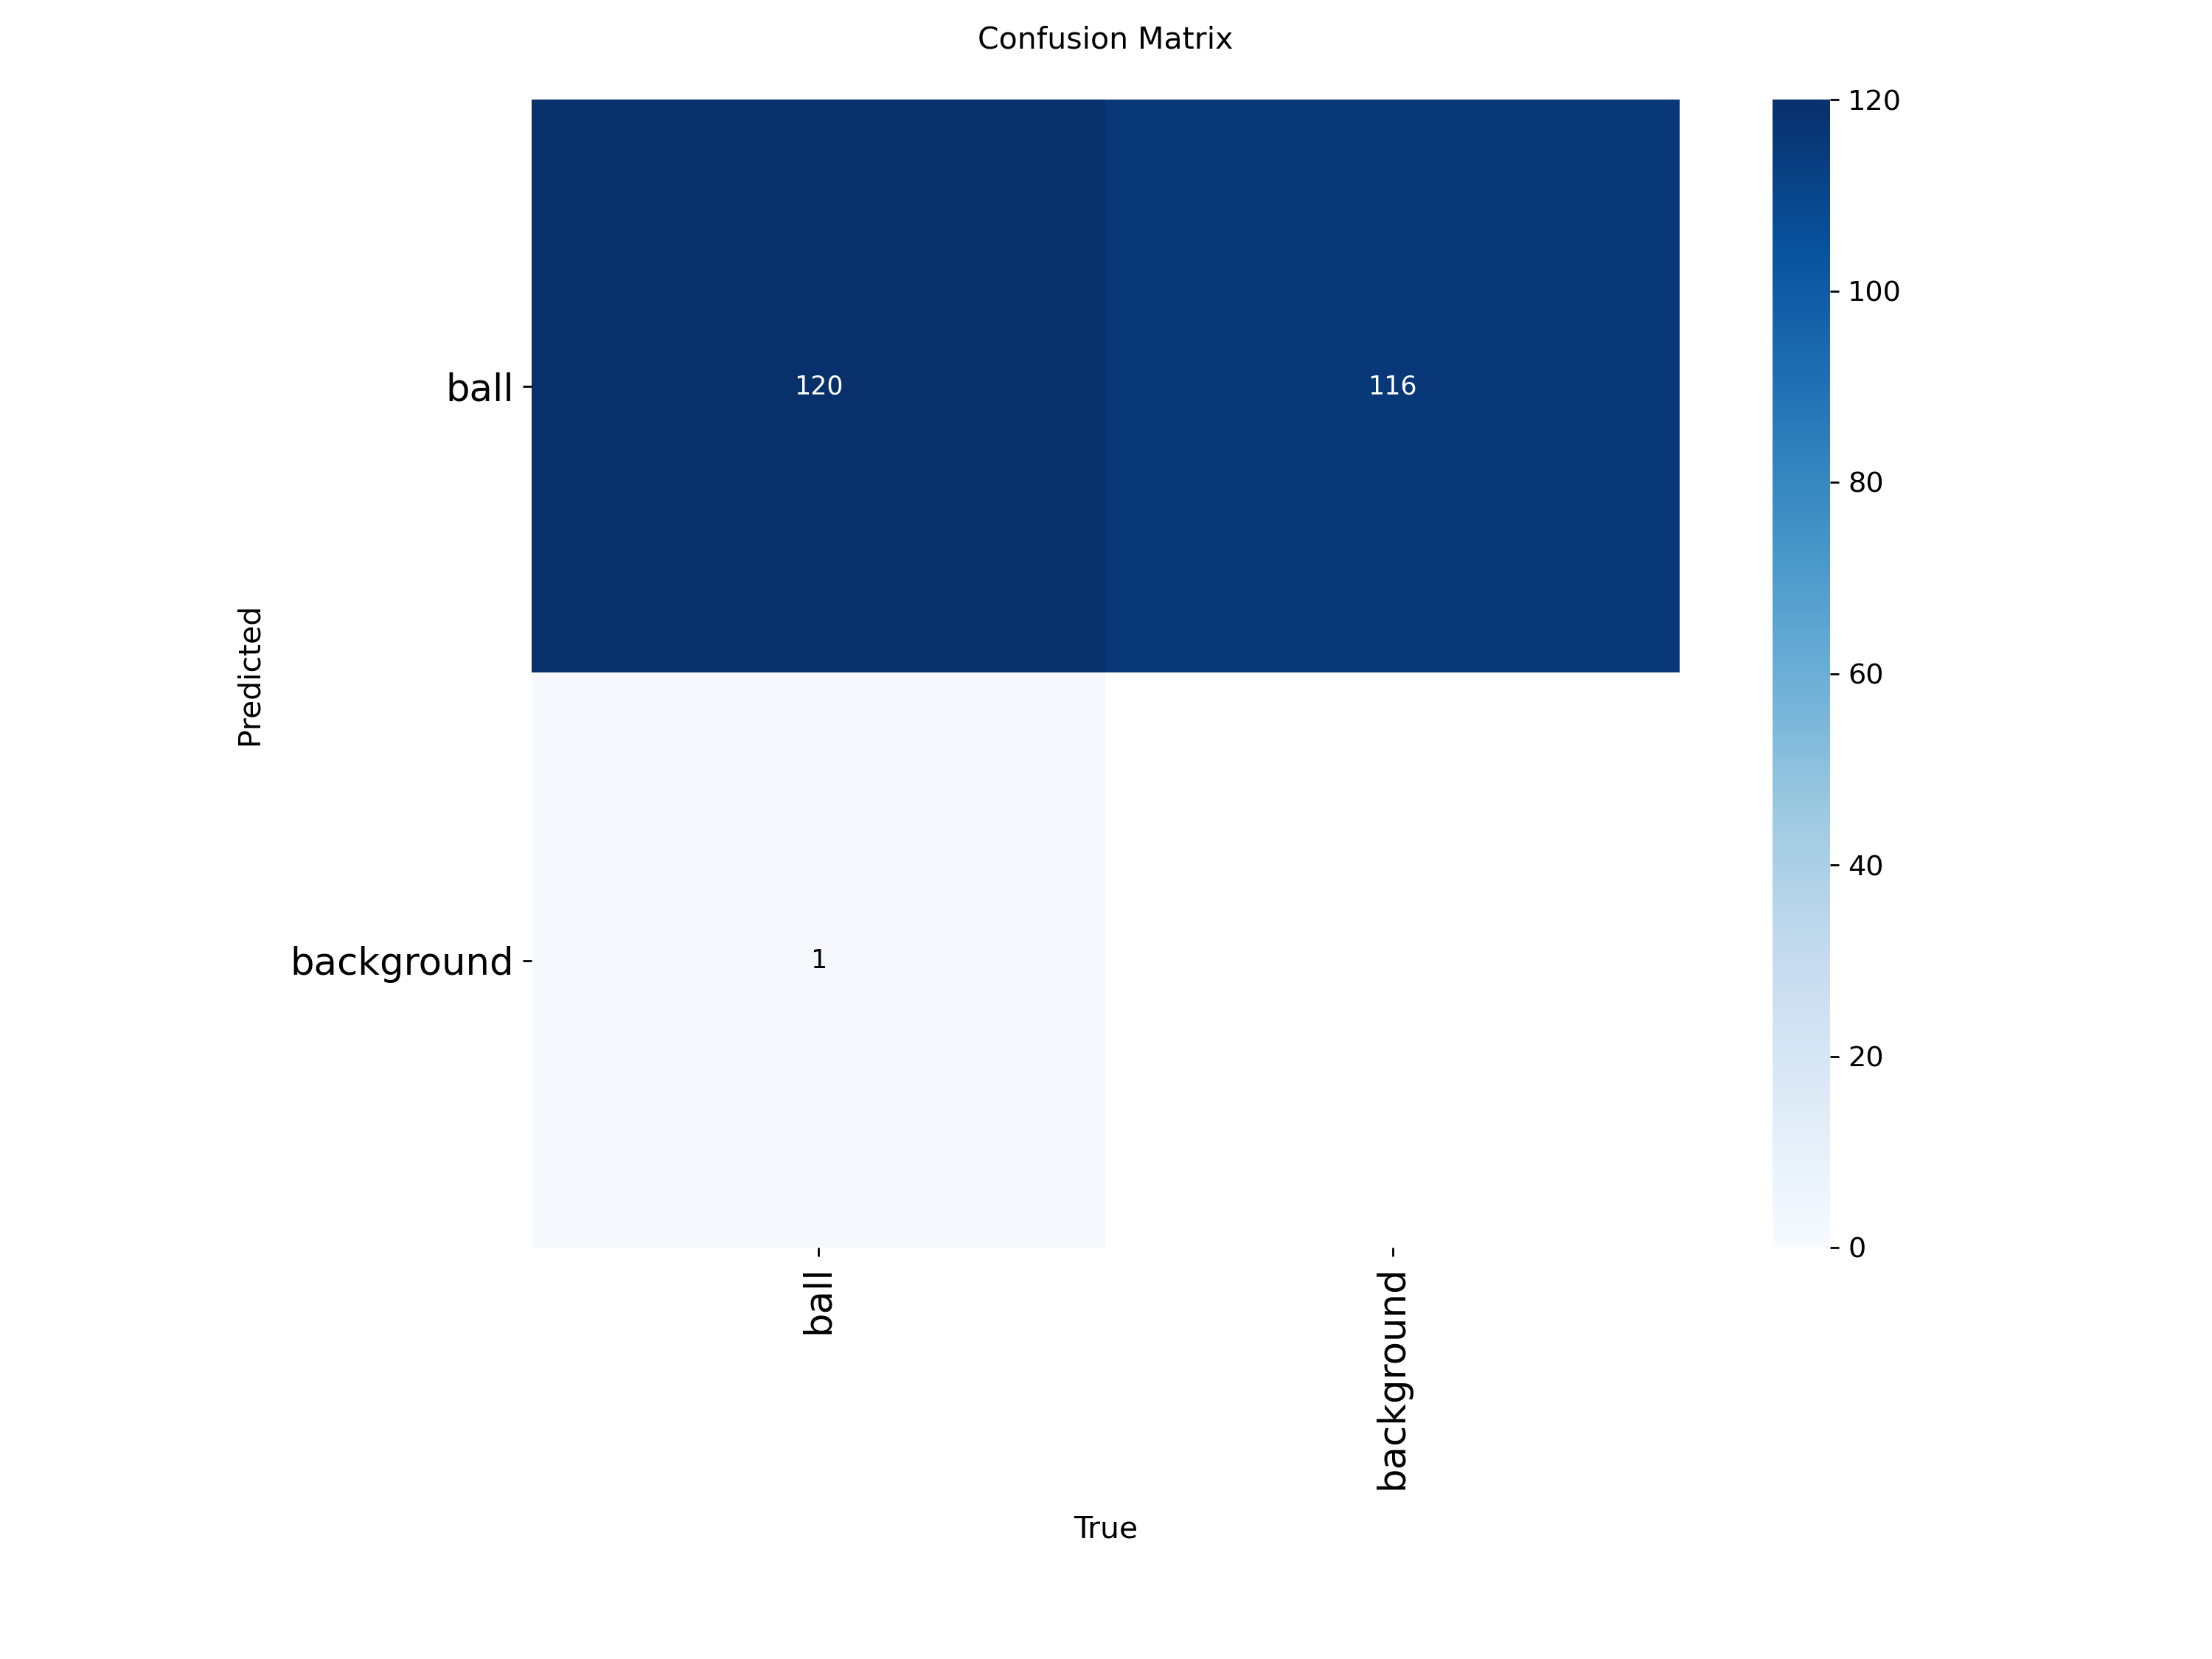

In [ ]:
%cd {HOME}
Image(filename=f'/content/runs/detect/yolo26s-2/confusion_matrix.png', width=600)

/content


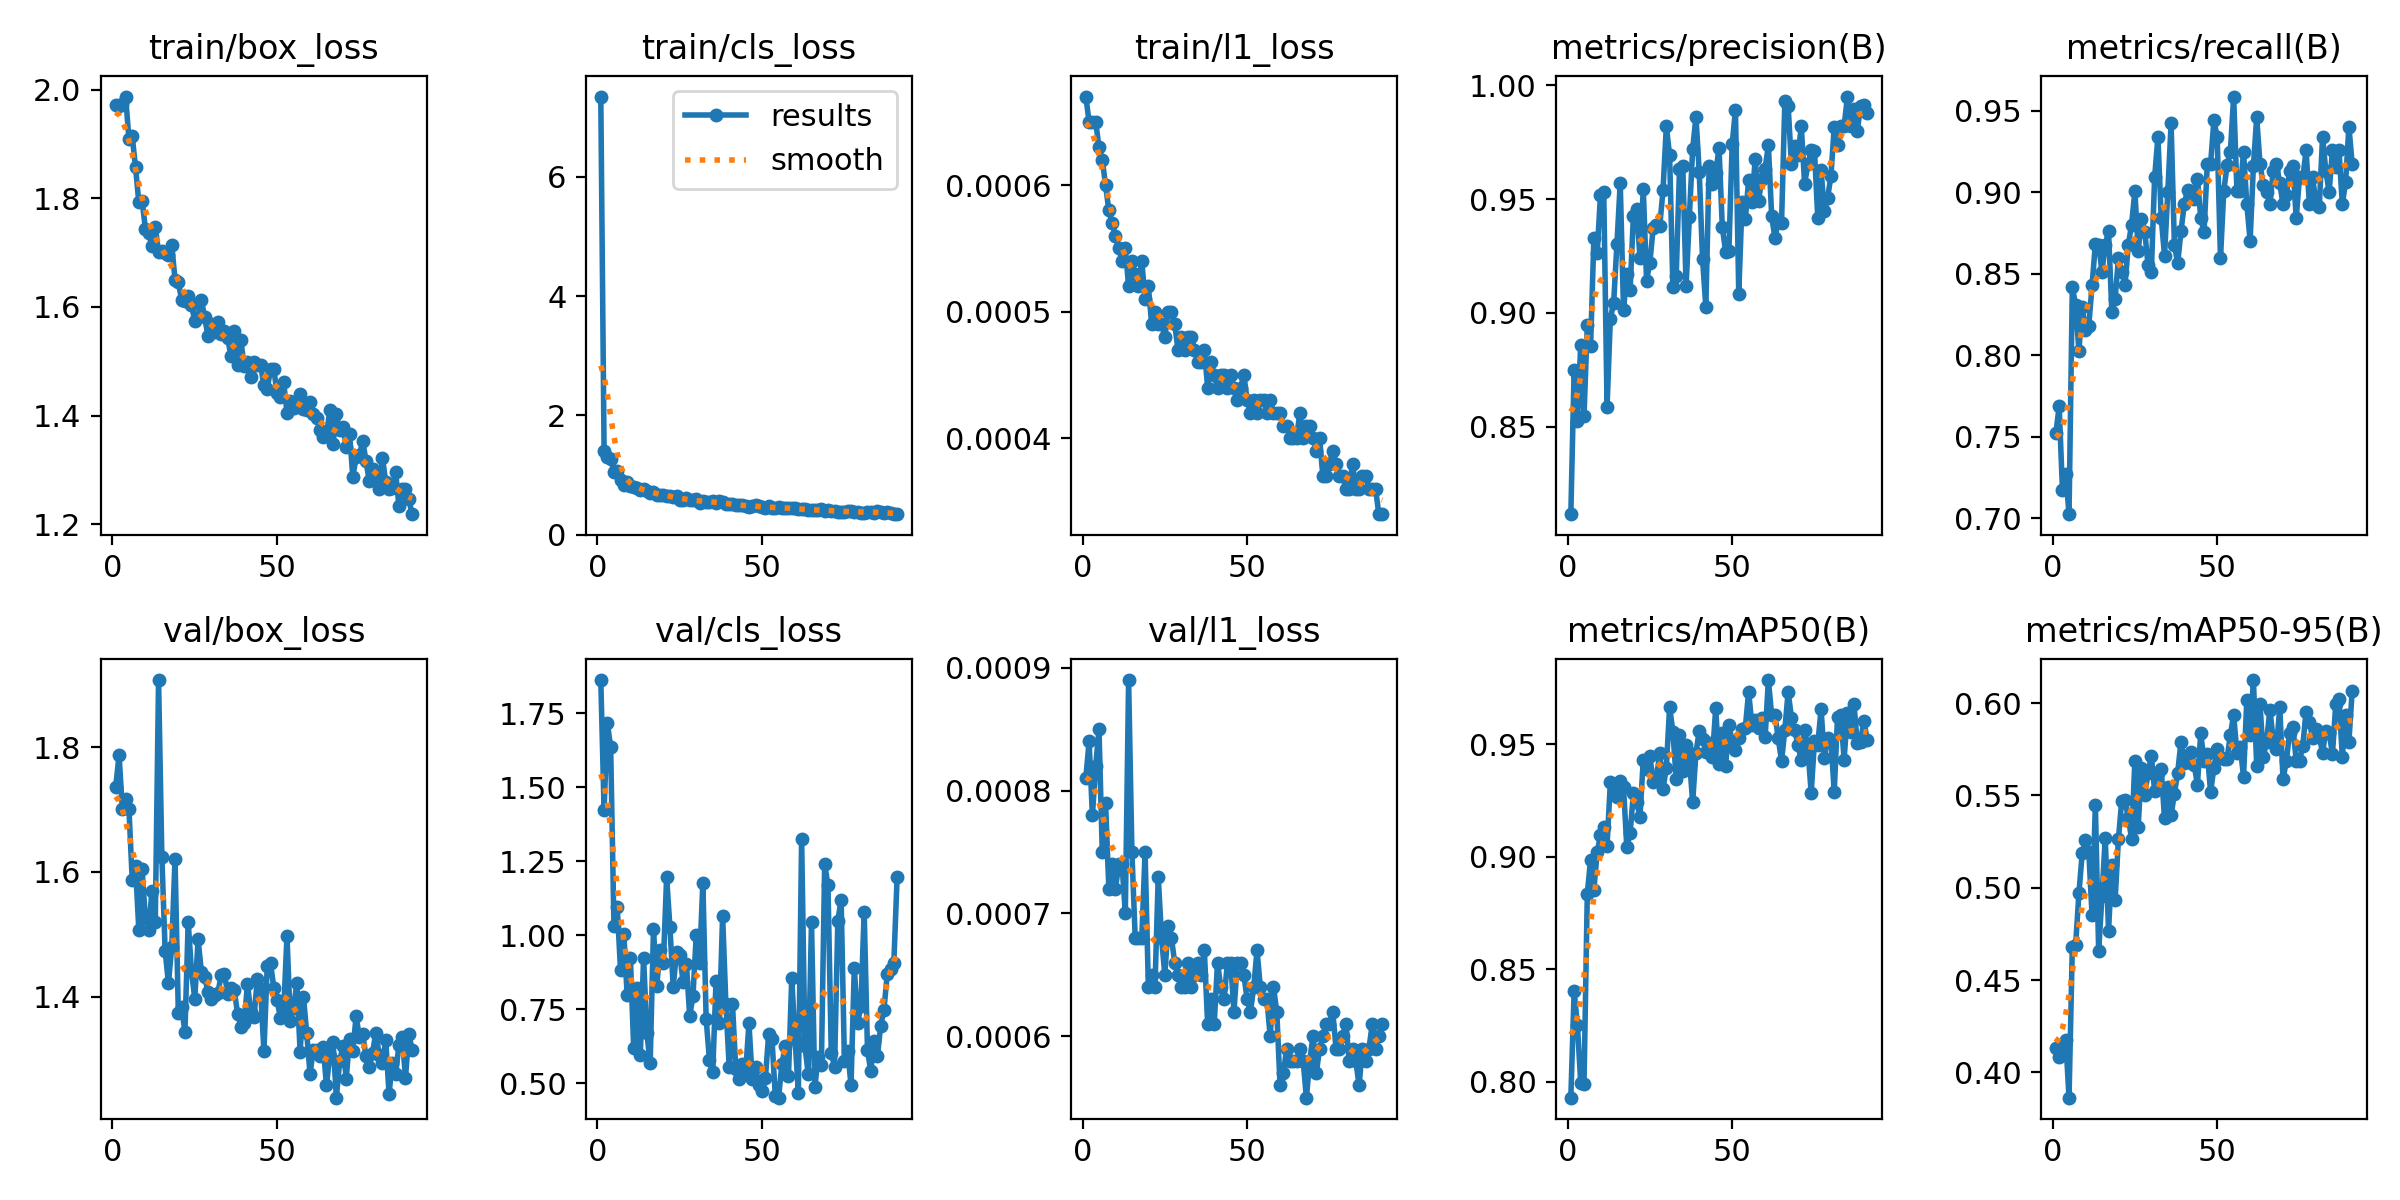

In [ ]:
%cd {HOME}
Image(filename=f'/content/runs/detect/yolo26s-2/results.png', width=600)

/content


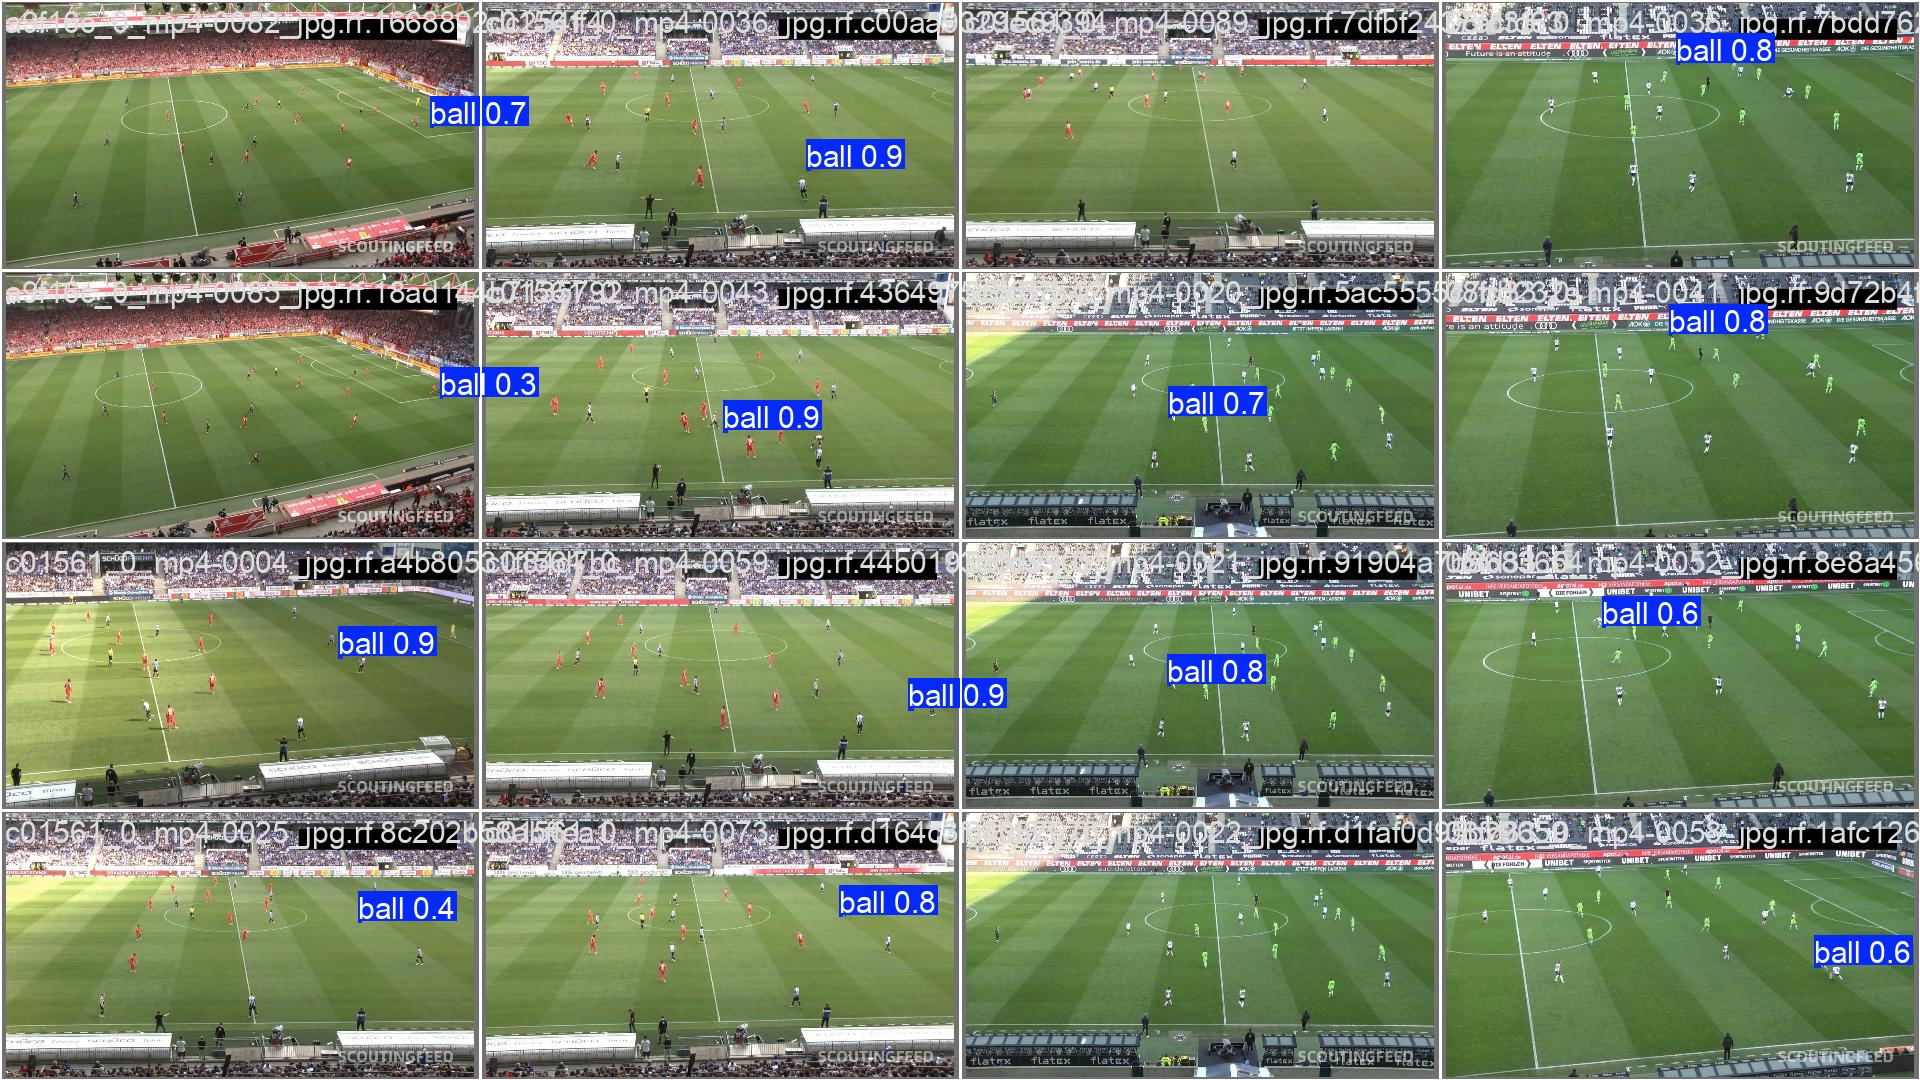

In [ ]:
%cd {HOME}
Image(filename=f'{HOME}/runs/detect/train/val_batch0_pred.jpg', width=600)

## Validate custom model

In [ ]:
%cd {HOME}

!yolo task=detect mode=val model={HOME}/runs/detect/train/weights/best.pt data={dataset.location}/data.yaml imgsz=1280

/content
Ultralytics YOLOv8.2.64 🚀 Python-3.10.12 torch-2.3.1+cu121 CUDA:0 (NVIDIA A100-SXM4-40GB, 40514MiB)
Model summary (fused): 268 layers, 68,124,531 parameters, 0 gradients, 257.4 GFLOPs
val: Scanning /content/datasets/football-ball-detection-2/valid/labels.cache... 121 images, 0 backgrounds, 0 corrupt: 100% 121/121 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% 8/8 [00:04<00:00,  1.69it/s]
                   all        121        121      0.926      0.832      0.932      0.611
Speed: 3.5ms preprocess, 13.7ms inference, 0.0ms loss, 10.9ms postprocess per image
Results saved to runs/detect/val
💡 Learn more at https://docs.ultralytics.com/modes/val


### Tactical inferences

Inferences with tiling

In [ ]:
from sahi import AutoDetectionModel
import numpy as np


def extract_predictions(prediction_result):
    xyxy = []
    scores = []
    class_ids = []

    for obj in prediction_result.object_prediction_list:
        # Bounding box: [x_min, y_min, x_max, y_max]
        xyxy.append(obj.bbox.to_xyxy())

        # Confidence score
        scores.append(obj.score.value)

        # Class ID
        class_ids.append(int(obj.category.id))

    return (
        np.array(xyxy, dtype=np.float32).reshape(-1, 4),
        np.array(scores, dtype=np.float32),
        np.array(class_ids, dtype=np.int32)
    )

In [27]:
from sahi.predict import get_sliced_prediction

model_path = "/content/drive/MyDrive/Hackathon/YOLO_models/yolo26s-2/weights/last.pt"

detection_model = AutoDetectionModel.from_pretrained(
    model_type="ultralytics",
    model_path=model_path,
    confidence_threshold=0.3,
    device='cuda',  # ou 'cuda:0'
)

import cv2
import pandas as pd
from ultralytics import YOLO

video_path = r'/content/drive/MyDrive/Copie de BAR-ATH_tactical.mp4'
cap = cv2.VideoCapture(video_path)
STARTER_FRAME = 11190
cap.set(cv2.CAP_PROP_POS_FRAMES, STARTER_FRAME)
frame_number = STARTER_FRAME
CSV_PATH = '/content/drive/MyDrive/Hackathon/first_half_sliced.csv'
rows = []

while cap.isOpened():
    ret, frame = cap.read()

    if not ret:
        break

    # frame is an image (NumPy array)
    print(f"Frame {frame_number}: {frame.shape}")

    h, w, _ = frame.shape

    result = get_sliced_prediction(
        frame,
        detection_model,
        slice_height=int(h/2) + 100,
        slice_width=int(w/2) + 100,
        overlap_height_ratio=0.1,
        overlap_width_ratio=0.1,
    )

    # results = model.predict(source=frame, conf=0.3, show=True, save=True)
    # Extract boxes, confidence scores and class IDs
    bboxes, scores, class_ids = extract_predictions(result)

    for bbox, score, class_id in zip(bboxes, scores, class_ids):
        rows.append({
            "frame": frame_number,
            "x1": float(bbox[0]),
            "y1": float(bbox[1]),
            "x2": float(bbox[2]),
            "y2": float(bbox[3]),
            "score": float(score),
            "class_id": int(class_id),
        })


    frame_number += 1

    if frame_number > 30000: # First half only
        break

columns = [
    "frame", "x1", "y1", "x2", "y2", "score", "class_id"
]

df = pd.DataFrame(rows, columns=columns)
df.to_csv(CSV_PATH, index=False)

print(df.head())
print(f"Processed {frame_number} frames")
print(f"Saved {len(df)} detections to {CSV_PATH}")






Streaming output truncated to the last 5000 lines.
Performing prediction on 4 slices.
Frame 27509: (1080, 1920, 3)
Performing prediction on 4 slices.
Frame 27510: (1080, 1920, 3)
Performing prediction on 4 slices.
Frame 27511: (1080, 1920, 3)
Performing prediction on 4 slices.
Frame 27512: (1080, 1920, 3)
Performing prediction on 4 slices.
Frame 27513: (1080, 1920, 3)
Performing prediction on 4 slices.
Frame 27514: (1080, 1920, 3)
Performing prediction on 4 slices.
Frame 27515: (1080, 1920, 3)
Performing prediction on 4 slices.
Frame 27516: (1080, 1920, 3)
Performing prediction on 4 slices.
Frame 27517: (1080, 1920, 3)
Performing prediction on 4 slices.
Frame 27518: (1080, 1920, 3)
Performing prediction on 4 slices.
Frame 27519: (1080, 1920, 3)
Performing prediction on 4 slices.
Frame 27520: (1080, 1920, 3)
Performing prediction on 4 slices.
Frame 27521: (1080, 1920, 3)
Performing prediction on 4 slices.
Frame 27522: (1080, 1920, 3)
Performing prediction on 4 slices.
Frame 27523: (1080

### Broacast inferences

Inferences without sliced method

In [21]:
import cv2
import pandas as pd
from ultralytics import YOLO

video_path = r'/content/drive/MyDrive/BAR-ATH_broadcast.mp4'
cap = cv2.VideoCapture(video_path)
STARTER_FRAME = 11190
cap.set(cv2.CAP_PROP_POS_FRAMES, STARTER_FRAME)
frame_number = STARTER_FRAME
CSV_PATH = '/content/drive/MyDrive/Hackathon/ball_broadcast_full_match.csv'
rows = []

# model = YOLO("/content/last.pt")

while cap.isOpened():
    ret, frame = cap.read()

    if not ret:
        break

    # frame is an image (NumPy array)
    print(f"Frame {frame_number}: {frame.shape}")

    detections = model.predict(source=frame, conf=0.3, show=True, save=True, imgsz=1280)[0].boxes
    # Extract boxes, confidence scores and class IDs
    for xyxy, score, class_id in zip(
        detections.xyxy,
        detections.conf,
        detections.cls,
    ):
        rows.append({
            "frame": frame_number,
            "x1": float(xyxy[0]),
            "y1": float(xyxy[1]),
            "x2": float(xyxy[2]),
            "y2": float(xyxy[3]),
            "score": float(score),
            "class_id": int(class_id),
        })


    frame_number += 1

    # if frame_number > 90651: # First half only
    # # if frame_number > STARTER_FRAME + 5: # First half only
    #     break

columns = [
    "frame", "x1", "y1", "x2", "y2", "score", "class_id"
]

df = pd.DataFrame(rows, columns=columns)
df.to_csv(CSV_PATH, index=False)

print(df.head())
print(f"Processed {frame_number} frames")
print(f"Saved {len(df)} detections to {CSV_PATH}")